<a href="https://colab.research.google.com/github/MiikanGod/Car-Fuel-Classification/blob/main/Analisis_dan_Klasifikasi_Jenis_Bahan_Bakar_Mobil_Berdasarkan_Performa_Mesin_Tahun_2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Mengimpor pustaka yang diperlukan untuk analisis dan visualisasi data
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

# Mengunggah file dataset 'Cars Datasets 2025.csv'
uploaded = files.upload()

Saving Cars Datasets 2025.csv to Cars Datasets 2025.csv


- import pandas as pd — Mengimpor Pandas untuk membaca, mengolah, dan menganalisis data berbentuk tabel. pd merupakan nama singkatnya.
- import numpy as np — Mengimpor NumPy untuk operasi numerik, termasuk penggunaan np.nan sebagai nilai kosong.
- import matplotlib.pyplot as plt — Mengimpor Matplotlib untuk membuat grafik dan visualisasi.
- import seaborn as sns — Mengimpor Seaborn untuk membuat grafik statistik, termasuk heatmap.
- from google.colab import files — Mengambil fitur upload file dari Google Colab.
- uploaded = files.upload() — Membuka dialog untuk mengunggah dataset dari komputer ke Google Colab.
Hasil upload disimpan dalam variabel uploaded.
Tujuan cell: Menyiapkan library yang dibutuhkan dan memasukkan file dataset mobil ke lingkungan kerja.

In [2]:
# 1. Membaca file CSV yang telah diunggah ke dalam DataFrame
df = pd.read_csv('Cars Datasets 2025.csv', encoding='latin1')

# 2. Melihat ukuran dataset (jumlah baris dan kolom)
print("Ukuran Dataset (Baris, Kolom):", df.shape)

# 3. Menampilkan informasi detail tipe data setiap kolom
print("\n--- Informasi Dataset ---")
display(df.info())

# 4. Mengecek apakah ada baris data yang duplikat
print("\nJumlah Data Duplikat:", df.duplicated().sum())

# 5. Mengecek jumlah nilai yang kosong (missing value)
print("\n--- Jumlah Missing Value ---")
display(df.isnull().sum())

Ukuran Dataset (Baris, Kolom): (1218, 11)

--- Informasi Dataset ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1218 entries, 0 to 1217
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   Company Names              1218 non-null   object
 1   Cars Names                 1218 non-null   object
 2   Engines                    1218 non-null   object
 3   CC/Battery Capacity        1215 non-null   object
 4   HorsePower                 1218 non-null   object
 5   Total Speed                1218 non-null   object
 6   Performance(0 - 100 )KM/H  1212 non-null   object
 7   Cars Prices                1218 non-null   object
 8   Fuel Types                 1218 non-null   object
 9   Seats                      1218 non-null   object
 10  Torque                     1217 non-null   object
dtypes: object(11)
memory usage: 104.8+ KB


None


Jumlah Data Duplikat: 4

--- Jumlah Missing Value ---


,0
Company Names,0
Cars Names,0
Engines,0
CC/Battery Capacity,3
HorsePower,0
Total Speed,0
Performance(0 - 100 )KM/H,6
Cars Prices,0
Fuel Types,0
Seats,0


pd.read_csv(...) membaca file CSV menjadi DataFrame bernama df. DataFrame adalah tabel yang terdiri dari baris dan kolom.

encoding='latin1' menentukan cara membaca karakter pada file.

df.shape menampilkan ukuran dataset dalam format (jumlah_baris, jumlah_kolom).

df.info() menampilkan nama kolom, jumlah data yang terisi, tipe data, dan penggunaan memori.

df.duplicated().sum() menghitung jumlah baris yang terduplikasi.

df.isnull().sum() menghitung banyaknya nilai kosong pada setiap kolom.

display() menampilkan hasil pemeriksaan di notebook.

Memahami kondisi awal dataset sebelum dibersihkan. Dari sini dapat diketahui ukuran data, tipe data, duplikasi, dan nilai kosong.

In [3]:
# 1. Menghapus baris data yang duplikat (ganda)
df = df.drop_duplicates()

# 2. Merapikan spasi berlebih pada nama kolom
df.columns = df.columns.str.strip()

# 3. Merapikan spasi berlebih pada data teks kategori
text_columns = ['Company Names', 'Cars Names', 'Engines', 'Fuel Types']
for col in text_columns:
    df[col] = df[col].astype('string').str.strip()

# 4. Melihat ukuran dataset terbaru setelah dibersihkan
print("Ukuran dataset setelah menghapus duplikat:", df.shape)

Ukuran dataset setelah menghapus duplikat: (1214, 11)


- df.drop_duplicates() menghapus baris yang isinya sama persis. Hasilnya disimpan kembali ke df.
- df.columns.str.strip() menghilangkan spasi di awal dan akhir nama kolom. Contohnya, " Fuel Types " menjadi "Fuel Types".
- text_columns adalah daftar kolom yang berisi teks atau kategori.
- for col in text_columns: menjalankan perintah berikutnya untuk setiap nama kolom dalam daftar.
- astype('string') mengubah kolom menjadi tipe data teks Pandas.
- .str.strip() membersihkan spasi berlebih di awal dan akhir isi sel.
- df.shape kembali digunakan untuk melihat ukuran dataset setelah duplikasi dihapus.

Tujuan : Membuat dataset lebih rapi dan mengurangi masalah akibat data ganda atau spasi yang tidak konsisten.

In [4]:
# 1. Membuat fungsi kustom untuk membersihkan dan mengubah teks spesifikasi menjadi angka
def to_number(value):
    if pd.isna(value):
        return np.nan

    value = str(value)
    value = value.replace(',', '')

    try:
        # Mengubah teks menjadi deretan angka, mengabaikan huruf/satuan
        numbers = pd.to_numeric(pd.Series(value.replace('-', ' ').split()), errors='coerce').dropna()
        if not numbers.empty:
            return float(numbers.mean())
    except:
        pass
    return np.nan

# 2. Menerapkan fungsi ke kolom-kolom spesifikasi teknis
df['Capacity_Numeric'] = df['CC/Battery Capacity'].apply(to_number)
df['HorsePower_Numeric'] = df['HorsePower'].apply(to_number)
df['TopSpeed_Numeric'] = df['Total Speed'].apply(to_number)
df['Acceleration_0_100'] = df['Performance(0 - 100 )KM/H'].apply(to_number)
df['Torque_Numeric'] = df['Torque'].apply(to_number)

# Khusus kolom jumlah kursi (Seats), cukup diubah langsung menjadi numerik
df['Seats_Numeric'] = pd.to_numeric(df['Seats'], errors='coerce')

# 3. Menampilkan hasil konversi beberapa kolom pertama
display(df[['Company Names', 'Cars Names', 'Capacity_Numeric', 'HorsePower_Numeric', 'TopSpeed_Numeric', 'Seats_Numeric']].head())

,Company Names,Cars Names,Capacity_Numeric,HorsePower_Numeric,TopSpeed_Numeric,Seats_Numeric
0,FERRARI,SF90 STRADALE,3990.0,963.0,340.0,2.0
1,ROLLS ROYCE,PHANTOM,6749.0,563.0,250.0,5.0
2,Ford,KA+,1200.0,77.5,165.0,5.0
3,MERCEDES,GT 63 S,3982.0,630.0,250.0,4.0
4,AUDI,AUDI R8 Gt,5204.0,602.0,320.0,2.0


- def to_number(value): mendefinisikan fungsi yang menerima satu nilai.
- pd.isna(value) memeriksa apakah nilai tersebut kosong. Jika kosong, fungsi mengembalikan np.nan.
- str(value) mengubah nilai menjadi teks agar dapat diproses.
- value.replace(',', '') menghapus tanda koma. Contohnya, "1,987" menjadi "1987".
- value.replace('-', ' ').split() mengganti tanda minus dengan spasi, kemudian memisahkan teks berdasarkan spasi.
- pd.to_numeric(..., errors='coerce') mencoba mengubah setiap bagian menjadi angka. Bagian yang tidak bisa diubah menjadi angka dijadikan nilai kosong.
- .dropna() membuang bagian yang gagal dikonversi.
- numbers.mean() menghitung rata-rata angka yang berhasil ditemukan.
- float(...) mengembalikan hasil dalam bentuk angka desimal.
- except: pass membuat fungsi tidak berhenti jika terjadi kesalahan pada bagian try.
- return np.nan mengembalikan nilai kosong jika tidak ditemukan angka yang dapat digunakan.
- apply(to_number) menjalankan fungsi pada setiap nilai dalam kolom, kemudian menyimpan hasilnya ke kolom baru.
- df[[...]].head() menampilkan lima baris pertama dari kolom yang dipilih untuk memeriksa hasil konversi.

Tujuan cell: Mengubah spesifikasi teknis menjadi bentuk numerik supaya dapat diproses oleh algoritma machine learning.

In [5]:
# 1. Menangani missing value pada kolom numerik menggunakan nilai median
numeric_columns = [
    'Capacity_Numeric',
    'HorsePower_Numeric',
    'TopSpeed_Numeric',
    'Acceleration_0_100',
    'Torque_Numeric',
    'Seats_Numeric'
]

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

# 2. Memeriksa kembali apakah masih ada missing value pada kolom numerik
print("Sisa Missing Value pada Kolom Numerik")
display(df[numeric_columns].isnull().sum())

# 3. Memeriksa jumlah data untuk setiap jenis bahan bakar (Fuel Types)
print("\n--- Sebaran Kategori Fuel Types ---")
display(df['Fuel Types'].value_counts())

Sisa Missing Value pada Kolom Numerik


,0
Capacity_Numeric,0
HorsePower_Numeric,0
TopSpeed_Numeric,0
Acceleration_0_100,0
Torque_Numeric,0
Seats_Numeric,0



--- Sebaran Kategori Fuel Types ---


,count
Fuel Types,
Petrol,869
Diesel,106
Electric,96
Hybrid,78
Petrol/Diesel,16
Petrol/Hybrid,16
Plug-in Hybrid,5
Hybrid (Petrol),4
Diesel/Petrol,4


- numeric_columns menyimpan daftar kolom numerik yang akan diperiksa.
- for col in numeric_columns: melakukan pengolahan pada setiap kolom.
- df[col].median() menghitung nilai tengah atau median dari kolom tersebut.
- fillna(...) mengganti nilai kosong dengan median.
- df[col] = ... menyimpan hasil penggantian ke dataset.
- display(df[numeric_columns].isnull().sum()) Memeriksa kembali apakah kolom numerik masih memiliki nilai kosong.
- display(df['Fuel Types'].value_counts()) Menghitung jumlah kemunculan masing-masing jenis bahan bakar sebelum kategorinya diseragamkan.

Tujuan: Mengisi data numerik yang kosong dan melihat distribusi awal jenis bahan bakar.

In [6]:
# 1. Membuat fungsi untuk menyeragamkan kategori jenis bahan bakar
def clean_fuel_type(val):
    if pd.isna(val):
        return 'Unknown'

    val = str(val).lower()

    if 'electric' in val and 'hybrid' not in val and 'plug' not in val and 'ev' in val:
        return 'Electric'
    elif 'electric' in val and 'hybrid' not in val and 'plug' not in val:
        return 'Electric'
    elif 'plug' in val:
        return 'Plug-in Hybrid'
    elif 'hybrid' in val:
        return 'Hybrid'
    elif 'diesel' in val and 'petrol' not in val:
        return 'Diesel'
    elif 'petrol' in val and 'diesel' not in val:
        return 'Petrol'
    elif 'hydrogen' in val:
        return 'Hydrogen'
    elif 'cng' in val:
        return 'CNG'
    else:
        return 'Petrol/Mixed' # Untuk kombinasi atau kategori lain

# 2. Menerapkan fungsi ke kolom Fuel Types dan membuat kolom baru
df['Fuel_Clean'] = df['Fuel Types'].apply(clean_fuel_type)

# 3. Melihat jumlah data pada setiap kategori baru yang lebih rapi
print("--- Sebaran Kategori Fuel Types Setelah Disederhanakan ---")
display(df['Fuel_Clean'].value_counts())

--- Sebaran Kategori Fuel Types Setelah Disederhanakan ---


,count
Fuel_Clean,
Petrol,873
Diesel,106
Hybrid,106
Electric,96
Petrol/Mixed,23
Plug-in Hybrid,7
Hydrogen,3


Fungsi ini mengelompokkan berbagai penulisan bahan bakar ke kategori yang lebih konsisten.
- pd.isna(val) memeriksa nilai kosong dan memberikan kategori Unknown.
- str(val).lower() mengubah teks menjadi huruf kecil sehingga pemeriksaan tidak bergantung pada kapitalisasi.
- 'electric' in val memeriksa apakah teks mengandung kata electric.
- 'hybrid' not in val dan 'plug' not in val digunakan untuk membedakan mobil listrik dari kategori hybrid.
- elif memeriksa kondisi lain secara berurutan.
- return mengembalikan label kategori yang cocok.
- else mengelompokkan jenis yang tidak cocok dengan aturan sebelumnya ke Petrol/Mixed.
- apply(clean_fuel_type) menjalankan fungsi untuk setiap baris pada kolom Fuel Types.
- Fuel_Clean merupakan kolom baru yang menyimpan kategori bahan bakar yang telah disederhanakan.
- value_counts() menghitung jumlah mobil dalam masing-masing kategori hasil.

Tujuan: Menyiapkan label bahan bakar yang konsisten untuk dijadikan target klasifikasi.

In [7]:
# 1. Menentukan Variabel Target (y)
y = df['Fuel_Clean']

# 2. Menentukan Variabel Fitur (X) / Prediktor
X = df[[
    'Company Names',
    'Engines',
    'Capacity_Numeric',
    'HorsePower_Numeric',
    'TopSpeed_Numeric',
    'Acceleration_0_100',
    'Torque_Numeric',
    'Seats_Numeric'
]]

# 3. Menampilkan informasi dimensi X dan Y serta melihat 5 baris pertama X
print("Dimensi Fitur (X):", X.shape)
print("Dimensi Target (y):", y.shape)

print("\n--- Contoh Data Fitur (X) ---")
display(X.head())

Dimensi Fitur (X): (1214, 8)
Dimensi Target (y): (1214,)

--- Contoh Data Fitur (X) ---


,Company Names,Engines,Capacity_Numeric,HorsePower_Numeric,TopSpeed_Numeric,Acceleration_0_100,Torque_Numeric,Seats_Numeric
0,FERRARI,V8,3990.0,963.0,340.0,2.5,800.0,2.0
1,ROLLS ROYCE,V12,6749.0,563.0,250.0,5.3,900.0,5.0
2,Ford,1.2L Petrol,1200.0,77.5,165.0,10.5,120.0,5.0
3,MERCEDES,V8,3982.0,630.0,250.0,3.2,900.0,4.0
4,AUDI,V10,5204.0,602.0,320.0,3.6,560.0,2.0


Pada machine learning, data dibagi menjadi dua bagian utama:
- X adalah fitur atau variabel input yang digunakan model untuk mempelajari pola.
- y adalah target atau label yang ingin diprediksi.
Dalam notebook ini, targetnya adalah Fuel_Clean, yaitu jenis bahan bakar mobil.
Fitur input yang dipakai meliputi merek, tipe mesin, kapasitas, tenaga, kecepatan maksimum, akselerasi, torsi, dan jumlah kursi.

kemudian

- print("Dimensi Fitur (X):", X.shape)
- print("Dimensi Target (y):", y.shape)
- display(X.head())

Menampilkan jumlah baris dan kolom pada fitur, ukuran target, serta lima contoh data fitur.

Tujuan cell: Menentukan informasi yang digunakan untuk memprediksi jenis bahan bakar dan label yang ingin dihasilkan.

In [8]:
from sklearn.model_selection import train_test_split

# Membagi data dengan porsi 80% untuk training dan 20% untuk testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Menampilkan informasi jumlah data setelah dibagi
print("Jumlah Data Training (Latih) :", len(X_train))
print("Jumlah Data Testing (Uji)    :", len(X_test))
print("Persentase Data Latih        :", (len(X_train) / len(X)) * 100, "%")

Jumlah Data Training (Latih) : 971
Jumlah Data Testing (Uji)    : 243
Persentase Data Latih        : 79.9835255354201 %


- train_test_split merupakan fungsi untuk membagi dataset.
- X dan y adalah data fitur dan target.
- test_size=0.20 menetapkan 20% data untuk pengujian dan sisanya 80% untuk pelatihan.
- random_state=42 membuat proses pembagian dapat diulang dengan hasil yang sama pada kondisi dataset dan lingkungan yang sama.
- X_train berisi fitur untuk melatih model.
- X_test berisi fitur untuk menguji model.
- y_train berisi label bahan bakar yang dipelajari model.
- y_test berisi label sebenarnya untuk dibandingkan dengan prediksi.
- len() menghitung jumlah baris. Pembagian jumlah data training dengan total data, kemudian dikalikan 100, menghasilkan persentase data latih.

Tujuan: Memisahkan data untuk pembelajaran dan evaluasi agar model dapat diuji pada data yang tidak digunakan untuk pelatihan.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Menentukan daftar kolom kategorikal dan numerik
categorical_features = ['Company Names', 'Engines']
numeric_features = [
    'Capacity_Numeric',
    'HorsePower_Numeric',
    'TopSpeed_Numeric',
    'Acceleration_0_100',
    'Torque_Numeric',
    'Seats_Numeric'
]

# 2. Membuat preprocessor untuk mentransformasi fitur
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

print("Preprocessor berhasil dibuat dan siap digunakan!")

Preprocessor berhasil dibuat dan siap digunakan!


Library yang diimpor:
- ColumnTransformer memungkinkan transformasi berbeda diterapkan pada kelompok kolom yang berbeda.
- OneHotEncoder mengubah fitur kategori menjadi representasi numerik.
- StandardScaler menstandarkan fitur numerik berdasarkan rata-rata dan simpangan baku.
- categorical_features berisi data kategori berbentuk teks. numeric_features berisi data angka.
- transformers berisi aturan transformasi.
- ('num', StandardScaler(), numeric_features) berarti kolom numerik diproses dengan StandardScaler.
- ('cat', OneHotEncoder(...), categorical_features) berarti kolom kategori diubah menggunakan OneHotEncoder.
- handle_unknown='ignore' membuat encoder dapat menangani kategori baru yang tidak ditemukan ketika pelatihan. Kategori tersebut tidak akan menyebabkan error karena tidak dikenal oleh encoder.

Contoh sederhana: nama merek seperti Toyota dan Honda dapat diubah menjadi kolom indikator numerik yang berbeda.

Tujuan: Mengubah fitur mentah menjadi format yang dapat digunakan oleh algoritma klasifikasi.

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier

# 1. Membuat Pipeline yang menggabungkan preprocessor dan algoritma Random Forest
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# 2. Melatih model menggunakan data training (X_train dan y_train)
model.fit(X_train, y_train)

print("Model Klasifikasi Berhasil Dilatih!")

Model Klasifikasi Berhasil Dilatih!


- Pipeline menggabungkan beberapa tahap pemrosesan dalam satu alur.
- RandomForestClassifier adalah algoritma klasifikasi yang menggunakan kumpulan pohon keputusan.

Pipeline terdiri dari dua tahap:
1. preprocessor — Mengubah fitur kategori dan numerik.
2. classifier — Melakukan klasifikasi dengan Random Forest.

- fit() membuat model mempelajari hubungan antara fitur mobil (X_train) dan label bahan bakarnya (y_train).

Random Forest membangun banyak pohon keputusan, kemudian menggabungkan hasil prediksi pohon-pohon tersebut untuk menentukan kelas yang dipilih.

Tujuan: Melatih model agar dapat memperkirakan jenis bahan bakar dari spesifikasi sebuah mobil.

Akurasi Model: 90.53%

--- Laporan Klasifikasi ---
                precision    recall  f1-score   support

        Diesel       1.00      0.70      0.83        27
      Electric       1.00      1.00      1.00        17
        Hybrid       0.94      0.58      0.71        26
      Hydrogen       0.00      0.00      0.00         1
        Petrol       0.89      1.00      0.94       168
  Petrol/Mixed       0.50      0.33      0.40         3
Plug-in Hybrid       0.00      0.00      0.00         1

      accuracy                           0.91       243
     macro avg       0.62      0.52      0.55       243
  weighted avg       0.90      0.91      0.89       243



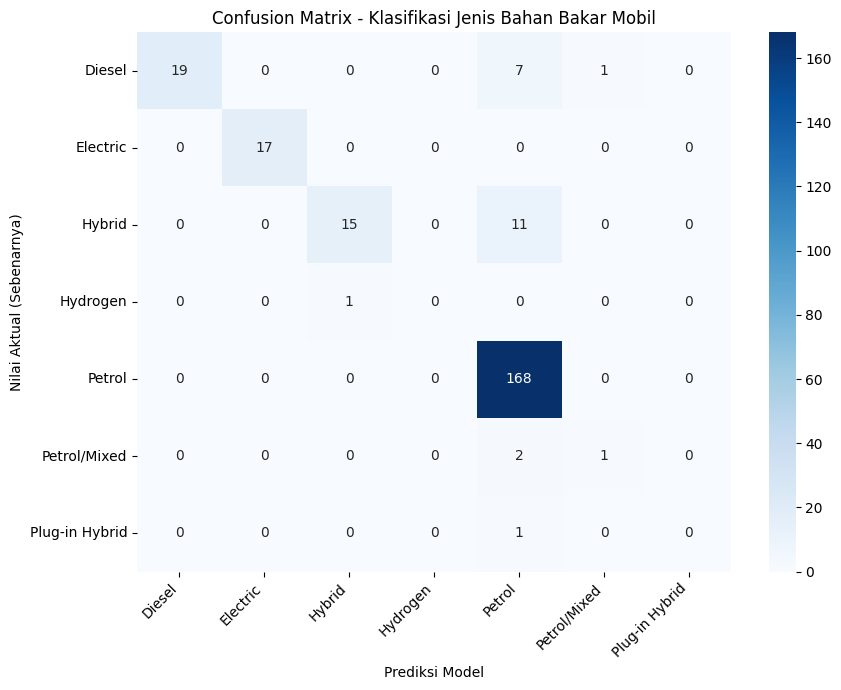

In [11]:
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# 1. Melakukan prediksi pada data testing
y_pred = model.predict(X_test)

# 2. Menghitung tingkat akurasi model
accuracy = accuracy_score(y_test, y_pred)
print(f"Akurasi Model: {accuracy * 100:.2f}%\n")

# 3. Menampilkan Laporan Klasifikasi lengkap
print("--- Laporan Klasifikasi ---")
print(classification_report(y_test, y_pred, zero_division=0))

# 4. Membuat visualisasi Confusion Matrix
plt.figure(figsize=(9, 7))
sns.heatmap(
    confusion_matrix(y_test, y_pred),
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)
plt.title('Confusion Matrix - Klasifikasi Jenis Bahan Bakar Mobil')
plt.xlabel('Prediksi Model')
plt.ylabel('Nilai Aktual (Sebenarnya)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- classification_report menghasilkan metrik evaluasi klasifikasi.
- accuracy_score menghitung persentase prediksi yang benar.
- confusion_matrix membandingkan label aktual dengan hasil prediksi.
- model.predict(X_test) menghasilkan prediksi bahan bakar untuk data testing. Hasilnya disimpan pada y_pred.

Menghitung akurasi:

accuracy = accuracy_score(y_test, y_pred)print(f"Akurasi Model: {accuracy * 100:.2f}%\n")

Akurasi dihitung dengan membagi jumlah prediksi benar dengan jumlah seluruh data pengujian, kemudian dikalikan 100%. Format :.2f menampilkan dua angka di belakang koma.

Laporan klasifikasi:
print(classification_report(y_test, y_pred, zero_division=0))

Laporan menampilkan beberapa metrik:
- Precision: Seberapa banyak prediksi suatu kelas yang benar.
- Recall: Seberapa banyak data aktual suatu kelas yang berhasil ditemukan model.
- F1-score: Gabungan precision dan recall.
- Support: Jumlah data aktual pada kelas tersebut.
- zero_division=0 menentukan nilai yang ditampilkan sebagai nol ketika suatu metrik tidak dapat dihitung karena tidak ada prediksi untuk kelas tersebut.

Penjelasan:
- plt.figure(figsize=(9, 7)) menentukan ukuran grafik.
- sns.heatmap(...) menampilkan matriks dalam bentuk kotak-kotak berwarna.
- confusion_matrix(y_test, y_pred) membandingkan label sebenarnya dan prediksi.
- annot=True menampilkan angka pada setiap kotak.
- fmt='d' menampilkan angka sebagai bilangan bulat.
- cmap='Blues' memilih gradasi warna biru.
- model.classes_ digunakan sebagai label kategori pada sumbu grafik.
- plt.title() memberikan judul.
- plt.xlabel() dan plt.ylabel() memberikan nama sumbu.
- rotation mengatur kemiringan tulisan kategori.
- plt.tight_layout() merapikan tata letak agar label tidak terpotong.
- plt.show() menampilkan grafik.

Cara membaca confusion matrix: Sumbu vertikal adalah kelas aktual, sedangkan sumbu horizontal adalah kelas prediksi. Angka pada diagonal menunjukkan jumlah prediksi yang benar. Angka di luar diagonal menunjukkan jumlah data yang salah diklasifikasikan.

In [12]:
# Membuat contoh data mobil baru untuk diprediksi oleh model
sample_car = pd.DataFrame({
    'Company Names': ['Toyota'],
    'Engines': ['2.0L 4-cylinder'],
    'Capacity_Numeric': [1987.0],
    'HorsePower_Numeric': [180.0],
    'TopSpeed_Numeric': [190.0],
    'Acceleration_0_100': [8.5],
    'Torque_Numeric': [200.0],
    'Seats_Numeric': [5.0]
})

# Melakukan prediksi jenis bahan bakar
predicted_fuel = model.predict(sample_car)
print(f"Prediksi Jenis Bahan Bakar untuk Mobil Tersebut: {predicted_fuel[0]}")

Prediksi Jenis Bahan Bakar untuk Mobil Tersebut: Hybrid


Kode ini membuat DataFrame berisi satu contoh mobil yang ingin diprediksi.

Setiap kolom harus sama dengan fitur yang digunakan ketika model dilatih.

Contohnya, mobil memiliki merek Toyota, kapasitas mesin 1987, tenaga 180 horsepower, dan jumlah kursi 5.

- model.predict(sample_car) memasukkan data mobil ke pipeline.
- Pipeline memproses data dengan preprocessor, lalu Random Forest menentukan prediksi jenis bahan bakar.
- predicted_fuel[0] mengambil hasil prediksi pertama karena contoh hanya berisi satu mobil.
- print() menampilkan kategori bahan bakar yang diprediksi.

Hasil prediksi yang keluar bergantung pada dataset dan model yang berhasil dilatih. Kode ini tidak cukup untuk memastikan Toyota contoh tersebut benar-benar menggunakan bahan bakar tertentu tanpa melihat output notebook.